# KAN-40 — EXP-02: Slow-Moving Risk Ground Truth & Labeling Benchmark

**Research Questions**:
- **RQ1**: Which GT definition best identifies slow-moving risk in ultra-sparse e-commerce demand?
- **RQ2**: Does DRR outperform absolute future quantity thresholds?
- **RQ3**: Do risk classes show sufficient discriminability across past signals?
- **RQ4**: Do High/Critical SKUs exhibit genuine slow-moving signals in the observation window?

**Strategies**: A (Absolute Future Demand) vs B (Demand Retention Ratio / DRR)

In [1]:
import sys, os, json
import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown

PROJECT_ROOT = Path(os.getcwd()).parent if os.getcwd().endswith('notebooks') else Path(os.getcwd())
sys.path.append(str(PROJECT_ROOT / 'scripts'))

from ground_truth_benchmark import main as run_gt_benchmark
gt_summary = run_gt_benchmark()

00:32:54 │ INFO    │ ╔══════════════════════════════════════════════════════════════════════╗


00:32:54 │ INFO    │ ║  EXP-02 — Slow-Moving Risk Ground Truth & Labeling Benchmark       ║


00:32:54 │ INFO    │ ╚══════════════════════════════════════════════════════════════════════╝


00:32:54 │ INFO    │ Loading datasets...


00:32:55 │ INFO    │ ─── Computing per-SKU metrics (past + future) ───


...

00:32:57 │ INFO    │   ✅ Saved: ground_truth_distribution.csv


00:32:57 │ INFO    │   ✅ Saved: ground_truth_validation.csv


00:32:57 │ INFO    │   ✅ Saved: ground_truth_summary.json


00:32:58 │ INFO    │   ✅ Saved chart: ground_truth_benchmark_chart.png


00:32:58 │ INFO    │ 
🎉 EXP-02 Ground Truth Benchmark completed in 3.5s


## 1. Label Distribution: Strategy A vs Strategy B

In [2]:
df_dist = pd.read_csv(PROJECT_ROOT / 'reports' / 'ground_truth_distribution.csv')
for strategy in ['A', 'B', 'Selected']:
    subset = df_dist[df_dist['strategy'] == strategy]
    display(Markdown(f'### Strategy {strategy}'))
    display(subset[['label', 'count', 'pct']].style
        .set_caption(f'Strategy {strategy} Distribution')
        .format({'pct': '{:.1f}%'})
    )

### Strategy A

,label,count,pct
0,CRITICAL,598,63.6%
1,HIGH_RISK,230,24.5%
2,MEDIUM_RISK,19,2.0%
3,LOW_RISK,93,9.9%


### Strategy B

,label,count,pct
4,CRITICAL,598,63.6%
5,HIGH_RISK,209,22.2%
6,MEDIUM_RISK,42,4.5%
7,LOW_RISK,91,9.7%


### Strategy Selected

,label,count,pct
8,CRITICAL,598,63.6%
9,HIGH_RISK,230,24.5%
10,MEDIUM_RISK,19,2.0%
11,LOW_RISK,93,9.9%


## 2. Validation: Past Signals by Risk Class

In [3]:
df_val = pd.read_csv(PROJECT_ROOT / 'reports' / 'ground_truth_validation.csv')
key_cols = ['label', 'n_skus', 'pct',
            'sales_velocity_90d_mean', 'dsls_mean', 'zero_rate_90d_mean',
            'demand_probability_mean', 'pct_intermittent', 'pct_lumpy']
cols_present = [c for c in key_cols if c in df_val.columns]
display(df_val[cols_present].style.set_caption('Selected Strategy — Signal Validation'))

,label,n_skus,pct,sales_velocity_90d_mean,dsls_mean,zero_rate_90d_mean,demand_probability_mean,pct_intermittent,pct_lumpy
0,CRITICAL,598,63.620000,0.029035,374.707358,0.988643,0.003498,45.300000,54.700000
1,HIGH_RISK,230,24.470000,0.037172,701.152174,0.981844,0.012540,91.700000,8.300000
2,MEDIUM_RISK,19,2.020000,1.126663,120.842105,0.775015,0.192390,42.100000,57.900000
3,LOW_RISK,93,9.890000,14.841428,67.569892,0.445705,0.589780,8.600000,91.400000


## 3. Discriminability Test Results

In [4]:
with open(PROJECT_ROOT / 'reports' / 'ground_truth_summary.json') as f:
    summary = json.load(f)

for strat in ['strategy_a', 'strategy_b']:
    disc = summary['discriminability'][strat]
    name = 'A' if 'a' in strat else 'B'
    display(Markdown(f'### Strategy {name}'))
    rows = []
    for sig, res in disc.items():
        rows.append({
            'Signal': sig,
            'Kruskal H': res.get('kruskal_H'),
            'p-value': res.get('kruskal_p'),
            'Cohens d': res.get('cohens_d'),
            'Effect': res.get('effect_size'),
            'Significant': '***' if res.get('significant') else '',
        })
    display(pd.DataFrame(rows).style.set_caption(f'Strategy {name} Discriminability'))

### Strategy A

,Signal,Kruskal H,p-value,Cohens d,Effect,Significant
0,sales_velocity_90d,384.917100,0.000000,-1.877000,large,***
1,dsls,257.993100,0.000000,0.997100,large,***
2,zero_rate_90d,383.851100,0.000000,4.714600,large,***
3,zero_rate_full,370.671200,0.000000,1.138900,large,***
4,adi,421.312400,0.000000,0.430700,small,***
5,cv2,360.734200,0.000000,-0.564000,medium,***
6,demand_probability,362.295800,0.000000,-5.262100,large,***
7,expected_demand_daily,350.076700,0.000000,-1.686500,large,***
8,past_total_sold,417.086000,0.000000,-1.232000,large,***
9,sales_last_30d,576.202800,0.000000,-1.879900,large,***


### Strategy A

,Signal,Kruskal H,p-value,Cohens d,Effect,Significant
0,sales_velocity_90d,371.985400,0.000000,-1.217200,large,***
1,dsls,293.798800,0.000000,0.904600,large,***
2,zero_rate_90d,376.051200,0.000000,2.430600,large,***
3,zero_rate_full,340.772100,0.000000,0.744300,medium,***
4,adi,381.144600,0.000000,0.384700,small,***
5,cv2,312.877000,0.000000,-0.227600,small,***
6,demand_probability,369.727600,0.000000,-2.833400,large,***
7,expected_demand_daily,355.653100,0.000000,-1.237600,large,***
8,past_total_sold,354.091600,0.000000,-0.946500,large,***
9,sales_last_30d,514.394100,0.000000,-1.324500,large,***


## 4. Strategy Agreement

In [5]:
agreement = summary['agreement']
print(f'Agreement: {agreement["agreement_pct"]:.1f}% ({agreement["agreement_count"]}/940)')
print(f'Disagreement: {agreement["disagreement_count"]} SKUs')
print()
print('Cross-tabulation (A -> B):')
for transition, count in agreement['cross_tabulation'].items():
    a_lbl, b_lbl = transition.split(chr(8594)) if chr(8594) in transition else transition.split('->')
    if a_lbl.strip() != b_lbl.strip():
        print(f'  {transition}: {count} SKUs')

Agreement: 92.3% (868/940)
Disagreement: 72 SKUs

Cross-tabulation (A -> B):
  LOW_RISK→MEDIUM_RISK: 22 SKUs
  HIGH_RISK→MEDIUM_RISK: 15 SKUs
  HIGH_RISK→LOW_RISK: 15 SKUs
  MEDIUM_RISK→LOW_RISK: 11 SKUs
  LOW_RISK→HIGH_RISK: 6 SKUs
  MEDIUM_RISK→HIGH_RISK: 3 SKUs


## 5. Visualization

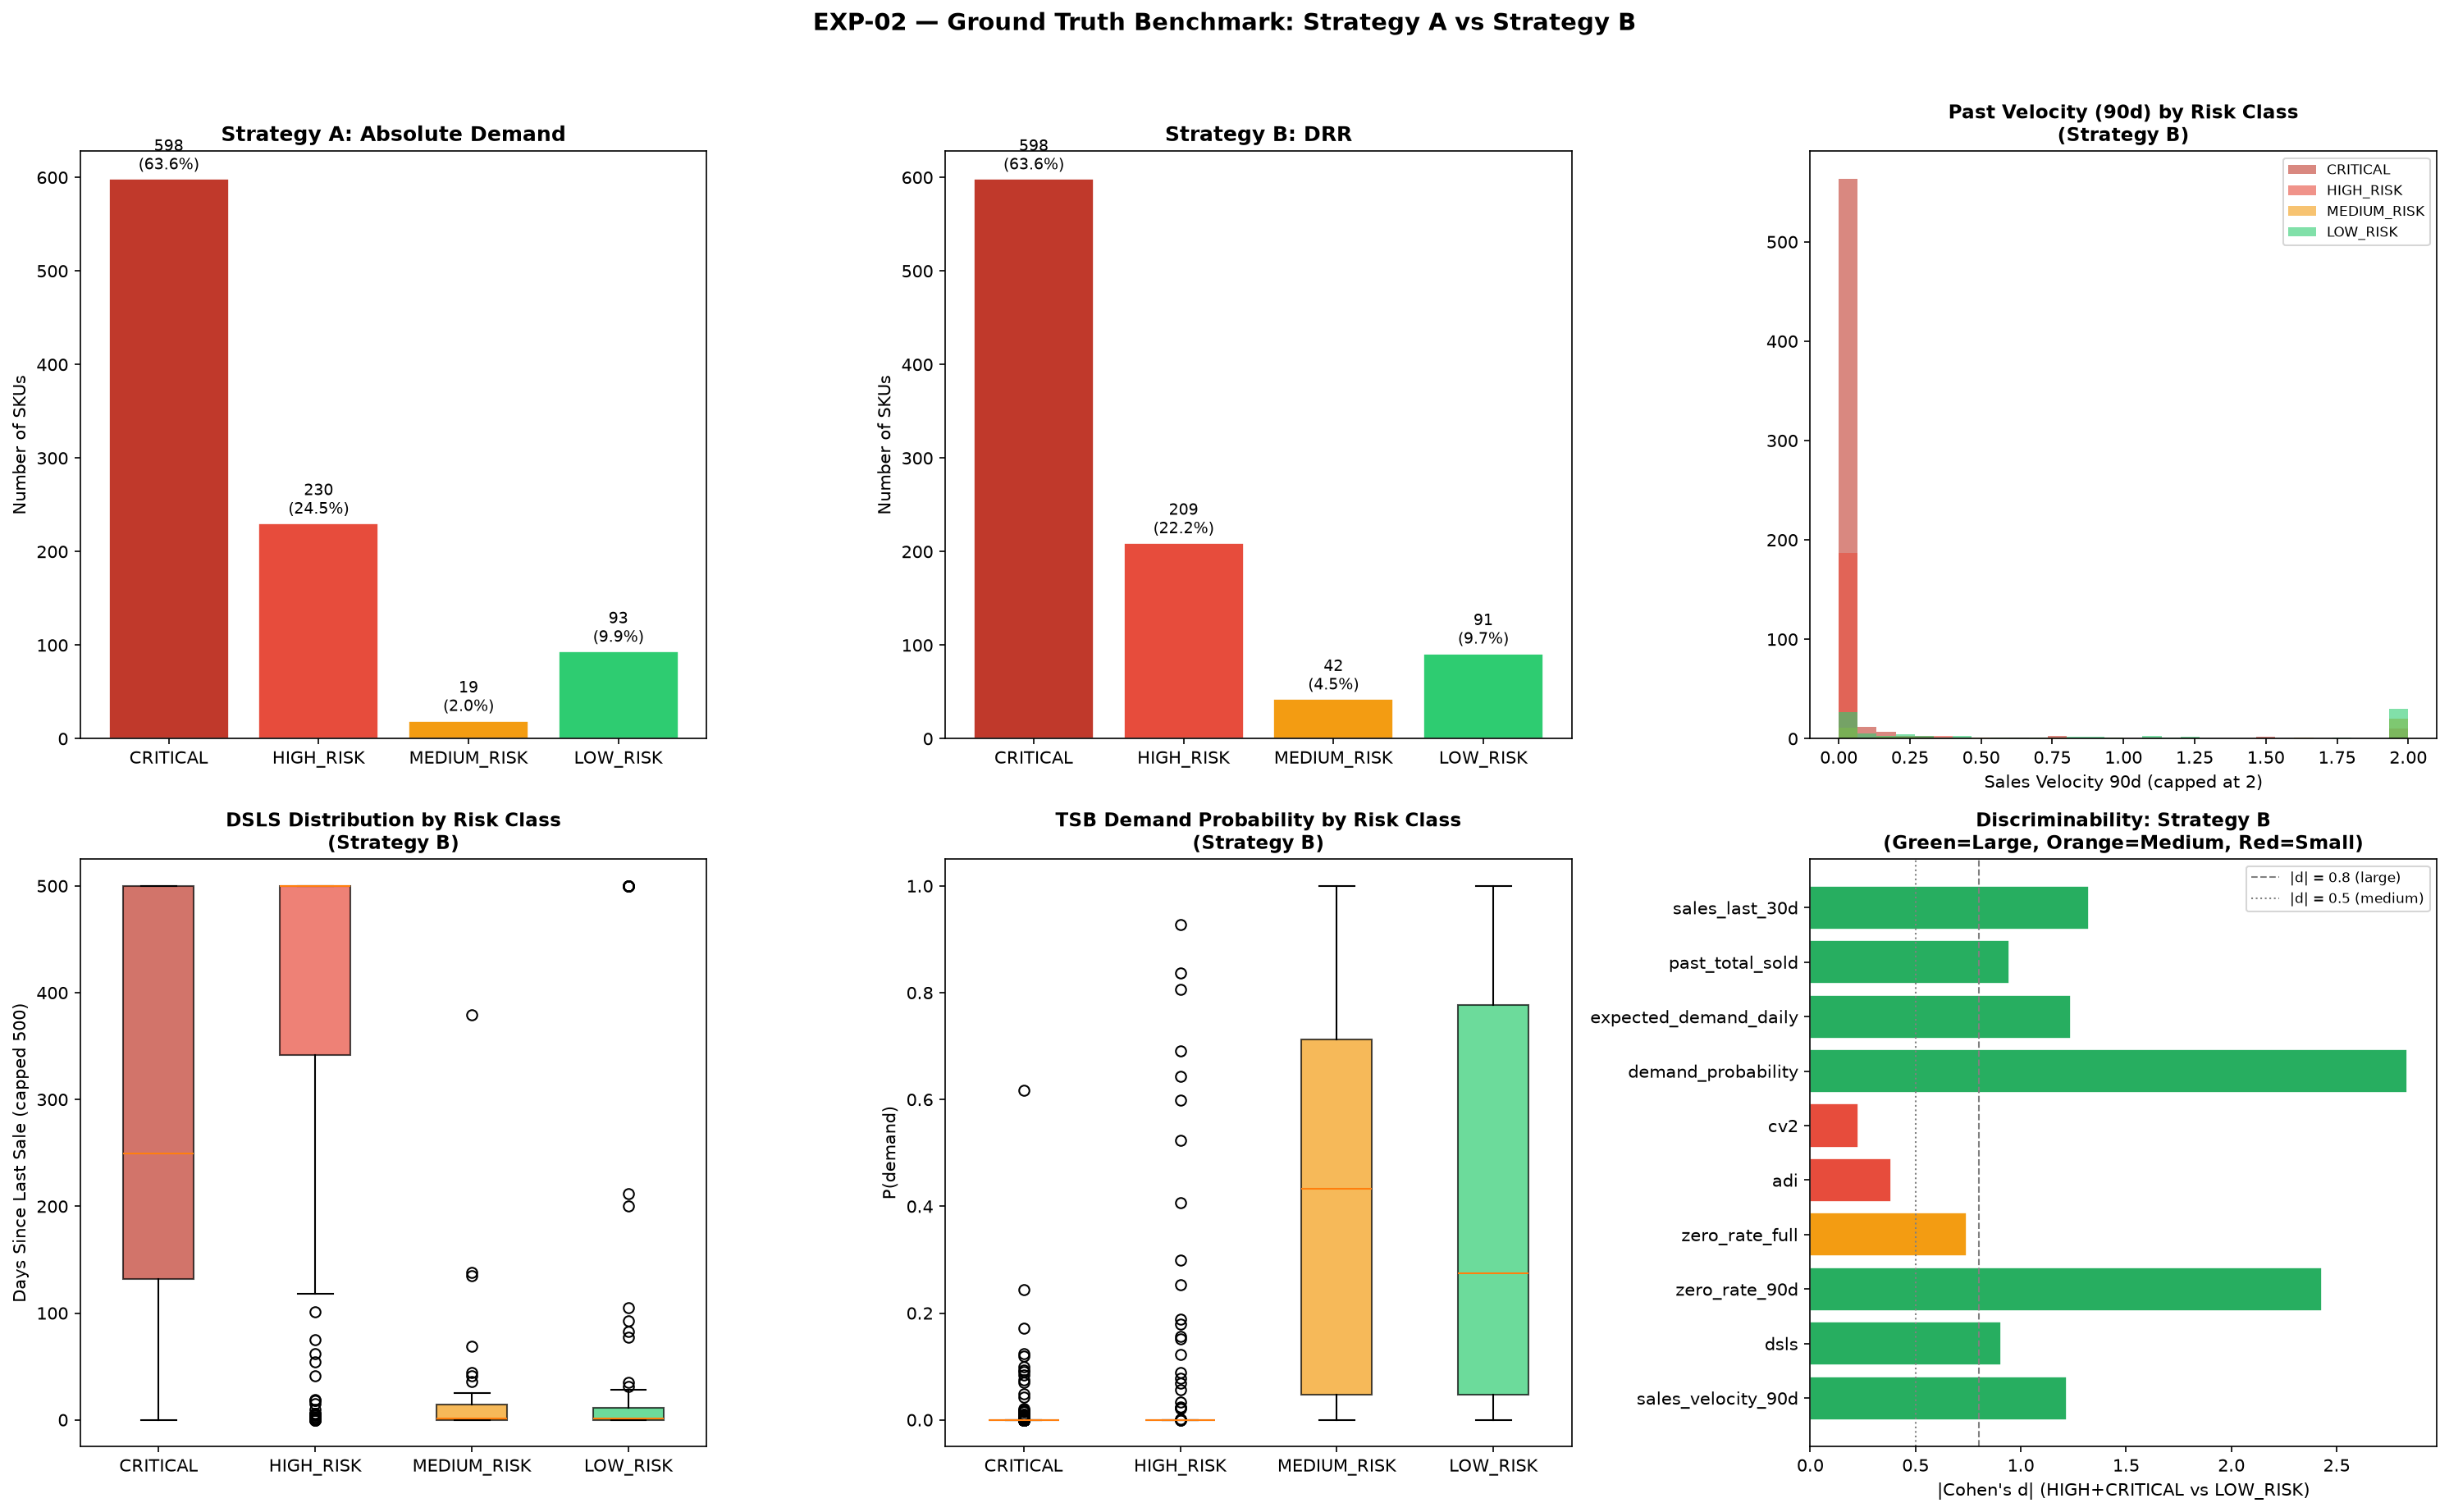

In [6]:
from IPython.display import Image
chart = PROJECT_ROOT / 'reports' / 'ground_truth_benchmark_chart.png'
if chart.exists():
    display(Image(filename=str(chart), width=1000))

## 6. Selected Strategy & Verdict

In [7]:
print('=' * 70)
print(f'SELECTED: Strategy {summary["selected_strategy"]}')
print(f'Reason: {summary["selection_reason"]}')
print('=' * 70)
print()
print('RQ Answers:')
for rq, answer in summary['rq_answers'].items():
    print(f'  {rq}: {answer}')

SELECTED: Strategy A
Reason: Absolute demand thresholds produce substantially higher discriminability between risk classes, suggesting future quantity alone is a strong proxy for slow-moving risk in this dataset.

RQ Answers:
  RQ1: Strategy A selected based on discriminability and theoretical soundness
  RQ2: DRR mean|d|=1.2251 vs Absolute mean|d|=1.9783
  RQ3: Strategy A produces 9 medium/large effect signals
  RQ4: See validation stats — High/Critical show elevated DSLS, high zero-rate, low velocity, low TSB demand_probability
